# 🏏 Pressure-Reliable Players: Step-by-Step Colab Notebook
**SupeRR Selector Season 2 · Round 1**

This notebook runs the analysis from start to finish and produces a **Top 10 list of batters and bowlers** based on their performance in high-pressure situations.

### How to run the notebook
1. Select **Runtime → Run all** in Google Colab.
2. When the first cell asks for a file, upload `data_pack.zip`.
3. The full run may take around **10–15 minutes** because several models need to be trained. Some cells may take longer. That is normal.

### Notebook plan

| Step | What happens |
|---|---|
| 1 | Load the data |
| 2 | Clean the data (extras, wides, no-balls and Super Overs) |
| 3 | Keep matches with reliable results |
| 4 | Calculate the match situation before each ball |
| 5 | Estimate the batting team's chance of winning |
| 6 | Measure pressure using the **Leverage Index** |
| 7 | Compare each delivery with its expected result |
| 8 | Rate and rank players, then show the Top 10 |

## Step 0: Import libraries and upload the data

In [1]:
import os, glob, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_style("whitegrid")
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer, PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# ---- data_pack.zip upload ----
try:
    from google.colab import files          # This works in Google Colab
    uploaded = files.upload()               # <-- yaha apni data_pack.zip chunein
    ZIP_NAME = list(uploaded.keys())[0]
except ImportError:                         # laptop par chalayein to zip ka naam yaha likhein
    ZIP_NAME = os.environ.get("DATA_ZIP", "data_pack.zip")

zipfile.ZipFile(ZIP_NAME).extractall("data")
DATA = os.path.dirname(glob.glob("data/**/ball_by_ball.csv", recursive=True)[0]) + "/"
print("Data folder:", DATA)

Saving 6af458274c1e8_data_pack.zip to 6af458274c1e8_data_pack.zip
Data folder: data/Data Pack/


## Step 1: Load the data

The analysis uses three files:

- `ball_by_ball.csv` — details of every delivery
- `matches.csv` — match results, targets and revised overs
- `competitions.csv` — identifies whether a match is an IPL, T20I or another T20 match
- `teams.csv` - information of  teams
- `playing_eleven.csv` - Playing XI and squad participation details
- `competition_team_player_mapping.csv` - competitions (like IPL or T20I), teams, and individual players



In [2]:
balls   = pd.read_csv(DATA + "ball_by_ball.csv")
matches = pd.read_csv(DATA + "matches.csv")
comps   = pd.read_csv(DATA + "competitions.csv")
teams   = pd.read_csv(DATA + "teams.csv")
playing_eleven = pd.read_csv(DATA + "playing_eleven.csv")
competitions_team = pd.read_csv(DATA + "competition_team_player_mapping.csv")

#


# format label: IPL / T20I / Other
matches = matches.merge(comps[["comp_id", "comp_name", "match_format"]], on="comp_id")
matches["fmt"] = np.where(matches.comp_name.str.contains("IPL"), "IPL",
                  np.where(matches.match_format == "T20I", "T20I", "Other"))
print("Deliveries:", len(balls), "| Matches:", balls.match_id.nunique())
balls.head(3)

Deliveries: 200999 | Matches: 867


,match_id,innings,overid,over_ball_num,innings_ball_num,batting_team_id,bowling_team_id,striker_id,striker_name,non_striker_id,non_striker_name,bowler_id,bowler_name,batting_type,bowling_type,...,is_six,is_wicket,dismissal_type_id,dismissal_type,dismissed_player_id,extras_type,extras1_runs,extras_2_runs,pace_or_spin,bowl_speed,stroke,delivery_style,over_or_around,on_or_off,delivery_ist_time
0,13511,1,1,1,1,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,...,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.0,Cover Drive,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC
1,13511,1,1,2,2,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,...,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.0,Flick,Inswing,Over,On-side,2022-01-23 00:00:00 UTC
2,13511,1,1,3,3,22,28,1187,Jason Roy,6273,Tom Banton,1772,Sheldon Cottrell,RHB,Left-arm fast-medium,...,False,False,NaN,NaN,NaN,NaN,0,0,Pace,0.0,Square Cut,Inswing,Over,Off-side,2022-01-23 00:00:00 UTC


## Step 2: Clean the data

This step prepares the delivery records for analysis:

1. **Remove Super Overs:** keep only the first two innings.
2. **Identify wides and no-balls:** these do not count as legal deliveries.
3. **Calculate team runs:** batter runs plus all extras.
4. **Calculate runs charged to the bowler:** batter runs, wides and no-ball runs. Byes and leg-byes are not charged to the bowler.
5. **Identify bowler wickets:** run-outs are not counted as wickets taken by the bowler.

In [3]:
balls = balls[balls.innings <= 2].copy()                      # Remove Super Overs
balls = balls.sort_values(["match_id", "innings", "innings_ball_num"]).reset_index(drop=True)

balls["extras_type"] = balls.extras_type.fillna("none")
balls["is_wide"]   = balls.extras_type == "wide"
balls["is_noball"] = balls.extras_type.isin(["Overstep", "other"])
balls["legal"]     = ~(balls.is_wide | balls.is_noball)

balls["team_runs"]   = balls.runs + balls.extras1_runs + balls.extras_2_runs
balls["bowler_runs"] = (balls.runs
                        + np.where(balls.is_wide | balls.is_noball, balls.extras1_runs, 0)
                        + np.where(balls.is_noball, balls.extras_2_runs, 0))

balls["is_wkt"]     = balls.is_wicket.astype(bool)                                   # Any type of wicket
balls["bowler_wkt"] = balls.is_wkt & balls.dismissal_type.isin(["Caught","Bowled","LBW","Stump","Hit Wicket"])
balls["bat_out"]    = balls.is_wkt & (balls.dismissed_player_id == balls.striker_id) & (balls.dismissal_type != "Retire Out")
balls[["runs","team_runs","bowler_runs","legal","bowler_wkt","bat_out"]].describe().loc[["mean","max"]]

,runs,team_runs,bowler_runs
mean,1.341086,1.41422,1.391285
max,6.000000,7.00000,7.000000


## Step 3: Keep only reliable matches

Some matches have no result, incomplete data or unusual conditions caused by rain. Keeping these matches could affect the model, so they are removed.

A match is kept only when:
- It has a clear result (not a tie or no result).
- Both innings are complete, or the chase has already finished.
- The winner calculated from the scores matches the winner recorded in the data.

> **Note:** The `revised_overs` column sometimes stores overs and sometimes stores balls. Values above 20 are treated as balls, so they are not multiplied by 6.

In [4]:
g = balls.groupby(["match_id", "innings"])
t = g.agg(runs=("team_runs","sum"), wkts=("is_wkt","sum"), nballs=("legal","sum")).reset_index()
t1 = t[t.innings == 1].set_index("match_id");  t2 = t[t.innings == 2].set_index("match_id")

ids  = sorted(set(balls.match_id) & set(matches.match_id))
info = matches.set_index("match_id").loc[ids].copy()
info["inn1_runs"], info["inn1_balls"], info["inn1_wkts"] = t1.runs, t1.nballs, t1.wkts
info["inn2_runs"], info["inn2_balls"], info["inn2_wkts"] = t2.runs, t2.nballs, t2.wkts
bt = balls.groupby(["match_id","innings"]).batting_team_id.first().unstack()
info["bat1"], info["bat2"] = bt[1], bt[2]

def to_balls(v):                       # Convert revised overs to balls
    return np.where(v.isna(), 120, np.where(v > 20, v, v * 6))
info["allot1"] = to_balls(info.first_inn_revised_overs)     # Total balls available in the first innings
info["allot2"] = to_balls(info.second_inn_revised_overs)    # Total balls available in the second innings
info["target"] = np.where(info.revised_target.notna(), info.revised_target, info.inn1_runs + 1)

info["chase_won"]     = info.inn2_runs >= info.target
info["derived_winner"] = np.where(info.chase_won, info.bat2, info.bat1)
inn1_ok = (info.inn1_balls >= info.allot1 - 3) | (info.inn1_wkts >= 9)
inn2_ok = info.chase_won | (info.inn2_balls >= info.allot2 - 3) | (info.inn2_wkts >= 9)
info["ok"] = info.win_team_id.notna() & (info.derived_winner == info.win_team_id) & inn1_ok & inn2_ok

print("Usable matches:", info.ok.sum(), "of", len(info))
print(info[info.ok].fmt.value_counts().to_string())

# Keep deliveries from valid matches and add match details
balls = balls[balls.match_id.isin(info.index[info.ok])].copy()
balls = balls.merge(info[["fmt","knock_out","allot1","allot2","target","win_team_id"]], left_on="match_id", right_index=True)
balls = balls.reset_index(drop=True)

Usable matches: 831 of 867
fmt
T20I     441
IPL      360
Other     30


## Step 4: Describe the match situation before each ball

For every delivery, we calculate the match situation **before the ball is bowled**:

- `balls_before` — legal balls already bowled. This is calculated using the over number so that a missing delivery does not shift later ball counts.
- `balls_left` — legal balls remaining in the innings.
- `wkts_lost` — wickets already lost.
- `crr` — current run rate, smoothed to avoid unstable values at the start of an innings.
- `runs_needed` and `rrr` — runs still needed and the required run rate during the second innings.

In [5]:
g = balls.groupby(["match_id", "innings"])
balls["runs_before"] = g.team_runs.cumsum() - balls.team_runs
balls["wkts_lost"]   = g.is_wkt.cumsum() - balls.is_wkt

balls["allot"] = np.where(balls.innings == 1, balls.allot1, balls.allot2)       # Total balls available in this innings
g_over = balls.groupby(["match_id", "innings", "overid"])
balls["balls_before"] = (balls.overid - 1) * 6 + (g_over.legal.cumsum() - balls.legal)
balls["balls_left"]   = (balls.allot - balls.balls_before).clip(lower=1)
balls["phase_frac"]   = balls.balls_before / balls.allot                         # Fraction of the innings already completed

balls["crr"]         = (balls.runs_before + 15) * 6 / (balls.balls_before + 12)  # Smoothed current run rate
balls["runs_needed"] = np.where(balls.innings == 2, balls.target - balls.runs_before, np.nan)
balls["rrr"]         = balls.runs_needed * 6 / balls.balls_left

balls["is_ipl"]  = (balls.fmt == "IPL").astype(int)
balls["is_t20i"] = (balls.fmt == "T20I").astype(int)
balls["ko"]      = balls.knock_out
balls["bat_win"] = (balls.win_team_id == balls.batting_team_id).astype(int)      # Whether the batting team won
balls[["innings","overid","runs_before","wkts_lost","balls_left","crr","runs_needed","rrr"]].iloc[[0, 100, 5000, 150000]]

,innings,overid,runs_before,wkts_lost,balls_left,crr,runs_needed,rrr
0,1,1,0,0,120.0,7.500000,NaN,NaN
100,1,17,85,7,23.0,5.504587,NaN,NaN
5000,1,15,102,7,33.0,7.090909,NaN,NaN
150000,1,18,113,7,14.0,6.508475,NaN,NaN


## Step 5: Build the win-probability model

**The idea:** use the match situation — balls remaining, wickets lost and runs needed — to estimate the batting team's chance of winning.

- A separate model is trained for the first and second innings.
- **Spline features and logistic regression** help the model learn smooth patterns.
- Model quality is checked using **out-of-fold AUC**. Each match is predicted by a model that was not trained on that match. The second-innings AUC is expected to be around 0.89. The first-innings AUC is around 0.68, which is lower because first-innings outcomes are harder to predict.

In [6]:
def make_features(inn, balls_before, allot, wkts, runs_before, target, is_ipl, is_t20i):
    """Create the model input columns from the match situation."""
    balls_left = np.maximum(allot - balls_before, 1)
    crr = (runs_before + 15) * 6 / (balls_before + 12)
    X = pd.DataFrame({"balls_left": balls_left, "wkts": wkts, "crr": crr,
                      "allot": allot, "ipl": is_ipl, "t20": is_t20i})
    if inn == 2:                                        # Chase: runs still needed
        need = target - runs_before
        X["runs_needed"] = np.clip(need, 0, None)
        X["rrr"]  = np.clip(need * 6 / balls_left, 0, 25)
        X["gap"]  = np.clip(X.rrr - crr, -15, 25)
    else:
        X["runs"] = runs_before
    return X

def current_features(x, inn):
    return make_features(inn, x.balls_before.values, x.allot.values, x.wkts_lost.values,
                         x.runs_before.values, x.target.values, x.is_ipl.values, x.is_t20i.values)

def new_wp_model(inn):
    cont = ["balls_left", "wkts", "crr"] + (["runs_needed", "rrr", "gap"] if inn == 2 else ["runs"])
    prep = ColumnTransformer([("spline", SplineTransformer(n_knots=3, degree=3, extrapolation="constant"), cont),
                              ("flags", "passthrough", ["ipl", "t20"])])
    return make_pipeline(prep, PolynomialFeatures(2, interaction_only=True, include_bias=False),
                         StandardScaler(), LogisticRegression(C=0.03, max_iter=200))

wp_models = {}
for inn in (1, 2):
    x = balls[balls.innings == inn]
    X, y, grp = current_features(x, inn), x.bat_win.values, x.match_id.values
    oof = np.zeros(len(x))
    for tr, te in GroupKFold(5).split(X, y, grp):                     # Five-fold validation, keeping each match in one fold
        oof[te] = new_wp_model(inn).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    print(f"Innings {inn}:  AUC = {roc_auc_score(y, oof):.3f}   Brier = {brier_score_loss(y, oof):.3f}")
    wp_models[inn] = new_wp_model(inn).fit(X, y)                      # Final model trained on all available data

Innings 1:  AUC = 0.682   Brier = 0.225
Innings 2:  AUC = 0.894   Brier = 0.132


## Step 6: Measure pressure with the Leverage Index

**The idea:** how much could the next delivery change the match?

For each delivery, the model considers eight possible outcomes: `0, 1, 2, 3, 4, 6, wicket, wide`.

1. Estimate the batting team's win probability after each possible outcome.
2. Measure the absolute change from the current win probability.
3. Weight each change by how often that outcome occurs in a similar situation, then add them together. This gives the **Leverage Index (LI)**.

A higher LI means the next ball has more potential to affect the result. The measure depends on the match situation before the ball, not on the shot the batter actually plays. A six therefore does not create pressure in the calculation.

> This cell may take around 2–3 minutes to run.

In [7]:
OUTCOMES = ["0", "1", "2", "3", "4", "6", "W", "wd"]
RUNS_OF  = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "6": 6, "W": 0, "wd": 1}

# --- Frequency of each outcome by innings, over and wicket group ---
def wkt_group(w): return pd.cut(w, [-1, 2, 5, 9], labels=[0, 1, 2]).astype(int)
tmp = balls[~balls.is_noball].copy()
tmp["oc"] = np.select([tmp.is_wide, tmp.is_wkt & tmp.legal, tmp.runs == 0, tmp.runs == 1, tmp.runs == 2,
                       tmp.runs == 3, tmp.runs.isin([4, 5]), tmp.runs == 6],
                      ["wd", "W", "0", "1", "2", "3", "4", "6"], default="0")
tmp["wg"] = wkt_group(tmp.wkts_lost)
outcome_prob = (tmp.groupby(["innings", "overid", "wg"]).oc.value_counts(normalize=True)
                   .unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0))

def wp_if(inn, x, oc):
    """Estimate the batting team win probability if the next outcome 'oc' ho jaye to batting team ki win-probability kya hogi."""
    bb, wk, rb = x.balls_before.values, x.wkts_lost.values, x.runs_before.values
    rb2 = rb + RUNS_OF[oc]
    bb2 = bb + (0 if oc == "wd" else 1)             # A wide does not use up a legal delivery
    wk2 = wk + (1 if oc == "W" else 0)
    p = wp_models[inn].predict_proba(make_features(inn, bb2, x.allot.values, wk2, rb2,
                                     x.target.values, x.is_ipl.values, x.is_t20i.values))[:, 1]
    if inn == 2:
        won  = (x.target.values - rb2) <= 0
        lost = (~won) & ((wk2 >= 10) | (bb2 >= x.allot.values))
        p = np.where(won, 1.0, np.where(lost, 0.0, p))
    else:                                           # First innings ends: estimate the second team's starting chance
        end = (wk2 >= 10) | (bb2 >= x.allot.values)
        if end.any():
            n = len(x)
            f2 = make_features(2, np.zeros(n), x.allot2.values if "allot2" in x else x.allot.values,
                               np.zeros(n), np.zeros(n), rb2 + 1, x.is_ipl.values, x.is_t20i.values)
            p = np.where(end, 1 - wp_models[2].predict_proba(f2)[:, 1], p)
    return p

balls["wp"] = np.nan;  balls["li"] = np.nan
for inn in (1, 2):
    idx = balls.index[balls.innings == inn]
    for s in range(0, len(idx), 25000):                              # Process in smaller batches to save memory
        ii = idx[s:s + 25000];  x = balls.loc[ii]
        wp_now = wp_models[inn].predict_proba(current_features(x, inn))[:, 1]
        key = pd.MultiIndex.from_arrays([x.innings, x.overid, wkt_group(x.wkts_lost)])
        P = outcome_prob.reindex(key).fillna(outcome_prob.mean()).values
        li = np.zeros(len(x))
        for k, oc in enumerate(OUTCOMES):
            li += P[:, k] * np.abs(wp_if(inn, x, oc) - wp_now)
        balls.loc[ii, "wp"] = wp_now;  balls.loc[ii, "li"] = li
print("Leverage Index ready ✅")

Leverage Index ready ✅


### Four ways to define a high-pressure delivery

The final result should not depend on just one cut-off, so we use four definitions:

| Name | Meaning |
|---|---|
| `main` | Deliveries in the top **20%** of LI in each innings |
| `top10` | Deliveries in the top **10%** of LI in each innings |
| `within_stage` | Top **20%** of LI separately within the powerplay, middle overs and death overs |
| `chase_only` | Top **20%** of LI in the second innings only |

The final ranking is based on the average score across these four definitions.

In [8]:
balls["li_pct"]    = balls.groupby("innings").li.rank(pct=True)           # LI percentile within each innings
balls["stage"]     = np.where(balls.phase_frac < 0.30, "PP", np.where(balls.phase_frac < 0.75, "Mid", "Death"))
balls["stage_pct"] = balls.groupby(["innings", "stage"]).li.rank(pct=True)

HP = {"main":         balls.li_pct >= 0.80,
      "top10":        balls.li_pct >= 0.90,
      "within_stage": balls.stage_pct >= 0.80,
      "chase_only":   (balls.li_pct >= 0.80) & (balls.innings == 2)}
balls["hp"] = HP["main"].astype(int)

# --- Check whether "high pressure" sach me alag hai? ---
f = balls[~balls.is_wide]
check = f.groupby(["innings", "hp"]).agg(balls=("runs", "size"), runs_per_over=("runs", lambda s: s.mean() * 6),
                                         wicket_pct=("bowler_wkt", lambda s: s.mean() * 100))
check["avg_wp_change_pct"] = balls.assign(d=(balls.groupby(["match_id","innings"]).wp.shift(-1) - balls.wp).abs() * 100
                                         ).groupby(["innings", "hp"]).d.mean()
check.round(2)    # hp=1 means high pressure; hp=0 means ordinary

balls  runs_per_over  wicket_pct  avg_wp_change_pct
innings hp                                                     
1       0   79127           8.32        4.91               0.93
        1   19705           9.00        6.19               2.26
2       0   72783           8.16        5.29               1.21
        1   18017           8.77        5.94               4.64

## Step 7: Measure performance on each delivery

Using strike rate or economy rate alone can be unfair. Some players perform in the death overs, while others play in easier situations. Instead, we compare every delivery with what an average player would be expected to do in the same situation.

1. **Value of a wicket (λ):** estimate how many runs a wicket is worth. The estimate uses the effect of a wicket and a run on win probability. Values are limited to the range 3–12.
2. **Expected-outcome models:** four machine-learning models estimate the runs an average batter would score, the chance of a batter getting out, the runs a bowler would concede and the chance of a bowler taking a wicket.
3. **Performance value:**
   - Batter = (runs − expected runs) − λ × (actual dismissal − expected dismissal chance)
   - Bowler = (expected runs conceded − actual runs conceded) + λ × (actual wicket − expected wicket chance)

> These cells may take around 3–5 minutes to run.

In [9]:
# ---- 7a. Estimate the value of a wicket in runs ----
balls["wp_next"] = balls.groupby(["match_id", "innings"]).wp.shift(-1)
first2 = balls[(balls.innings == 2) & (balls.balls_before == 0)].groupby("match_id").wp.first()
last   = balls.groupby(["match_id", "innings"]).cumcount(ascending=False) == 0
balls.loc[last & (balls.innings == 1), "wp_next"] = 1 - balls.loc[last & (balls.innings == 1), "match_id"].map(first2)
balls.loc[last & (balls.innings == 2), "wp_next"] = balls.loc[last & (balls.innings == 2), "bat_win"].astype(float)
balls["wp_next"] = balls.wp_next.fillna(balls.wp)
balls["dwp"] = balls.wp_next - balls.wp                      # Change in win probability caused by this delivery

rows = []
for (inn, st, hp), x in balls.groupby(["innings", "stage", "hp"]):
    A = np.c_[np.ones(len(x)), x.team_runs.values, x.is_wkt.values.astype(float)]
    coef = np.linalg.lstsq(A, x.dwp.values, rcond=None)[0]   # Model win-probability change using runs and wickets
    rows.append((inn, st, hp, -coef[2] / coef[1]))
lam = pd.DataFrame(rows, columns=["innings", "stage", "hp", "lam"])
lam["lam"] = lam.lam.clip(3, 12)                              # Keep the estimate within a reasonable range
balls = balls.merge(lam, on=["innings", "stage", "hp"], how="left")
print(lam.round(2).to_string(index=False))

 innings stage  hp   lam
       1 Death   0  6.34
       1 Death   1  5.58
       1   Mid   0 10.29
       1   Mid   1  5.86
       1    PP   0 12.00
       1    PP   1  6.33
       2 Death   0  3.12
       2 Death   1  3.02
       2   Mid   0  5.77
       2   Mid   1  5.98
       2    PP   0  9.72
       2    PP   1  5.28


In [10]:
# ---- 7b. Models for expected runs and wickets ----
balls["spin"] = (balls.pace_or_spin == "Spin").astype(int)
balls["lhb"]  = (balls.batting_type == "LHB").astype(int)
balls["ord_b"] = pd.cut(balls.batting_order, [0, 2, 4, 6, 20], labels=[1, 2, 3, 4]).astype(float)

BASE = ["innings", "balls_before", "balls_left", "wkts_lost", "crr", "rrr", "runs_needed",
        "allot", "is_ipl", "is_t20i", "ko", "spin", "lhb"]
BAT_FEATS, BOWL_FEATS = BASE + ["ord_b"], BASE        # Include batting order for batters to account for their role

def expected(df, feats, target, classifier):
    """Make out-of-fold predictions so each match is predicted by a model that did not train on it. har match ki prediction us model se jo us match par train hua hi nahi."""
    X, y = df[feats], df[target].values.astype(float)
    out = np.zeros(len(df))
    Model = HistGradientBoostingClassifier if classifier else HistGradientBoostingRegressor
    for tr, te in GroupKFold(5).split(X, y, df.match_id.values):
        m = Model(max_depth=5, learning_rate=0.06, max_iter=120, min_samples_leaf=200,
                  l2_regularization=3.0, random_state=0).fit(X.iloc[tr], y[tr])
        out[te] = m.predict_proba(X.iloc[te])[:, 1] if classifier else m.predict(X.iloc[te])
    return out

faced = balls.index[~balls.is_wide]                        # A batter does not face a wide as a legal delivery
balls["exp_runs"] = np.nan;  balls["exp_out"] = np.nan
balls.loc[faced, "exp_runs"] = expected(balls.loc[faced], BAT_FEATS, "runs", False);          print("1/4 done")
balls.loc[faced, "exp_out"]  = expected(balls.loc[faced], BAT_FEATS, "bat_out", True);        print("2/4 done")
balls["exp_conc"] = expected(balls, BOWL_FEATS, "bowler_runs", False);                        print("3/4 done")
balls["exp_wkt"]  = expected(balls, BOWL_FEATS, "bowler_wkt", True);                          print("4/4 done")

# ---- 7c. Calculate the final value for each delivery ----
balls["v_bat"]  = (balls.runs - balls.exp_runs) - balls.lam * (balls.bat_out.astype(float) - balls.exp_out)
balls["v_bowl"] = (balls.exp_conc - balls.bowler_runs) + balls.lam * (balls.bowler_wkt.astype(float) - balls.exp_wkt)
print("Value per ball ready ✅")

1/4 done
2/4 done
3/4 done
4/4 done
Value per ball ready ✅


## Step 8: Rate and rank the players

**Why is this needed?** A player may have only 200–300 high-pressure deliveries in the data. With a small sample, luck can have a noticeable effect. We use **shrinkage (empirical Bayes)** to reduce this problem. It moves estimates based on limited data closer to the league average.

Each player's rating uses three parts:

1. **Usual skill (μ):** the player's average value on ordinary deliveries.
2. **Pressure effect (δ):** how much the player's performance changes under pressure compared with their usual level. This estimate is also adjusted for limited data.
3. **Consistency:** the share of qualifying matches (at least four high-pressure deliveries) in which the player's pressure value was zero or higher.

**Level** = μ + δ

**Final score** = 0.6 × level + 0.2 × pressure effect + 0.2 × consistency

The three parts are standardised before they are combined.

A player is eligible for the main ranking only if they have at least **100 high-pressure deliveries, 150 ordinary deliveries and 12 pressure-match appearances**.

In [11]:
def make_player_match_table(d, pid, vcol, hp_mask):
    """Count and sum each player high-pressure and ordinary deliveries in every match. pressure balls ka count/sum aur normal balls ka count/sum."""
    x = pd.DataFrame({"pid": d[pid].values, "mid": d.match_id.values,
                      "v": d[vcol].values, "hp": hp_mask.loc[d.index].values})
    a = x.groupby(["pid", "mid", "hp"]).v.agg(["size", "sum"]).unstack("hp", fill_value=0)
    a.columns = ["n_o", "n_h", "s_o", "s_h"]            # o = ordinary; h = high pressure
    a = a.reset_index()
    a["app"] = (a.n_h >= 4).astype(float)                       # Did the player have a qualifying pressure appearance in this match?
    a["pos"] = ((a.n_h >= 4) & (a.s_h >= 0)).astype(float)      # Was the pressure value zero or higher?
    return a, x[x.hp].v.var(), x[~x.hp].v.var()

def rate_players(pm, var_h, var_o, w=None, hyp=None, min_h=100, min_o=150, min_app=12, wts=(.6, .2, .2)):
    """Calculate the shrinkage-based rating. w contains bootstrap match weights; hyp contains fixed shrinkage values. w = match weights (bootstrap ke liye), hyp = fixed shrinkage numbers."""
    cols = ["n_o", "n_h", "s_o", "s_h", "app", "pos"]
    if w is not None:
        pm = pm.copy();  pm[cols] = pm[cols].mul(pm.mid.map(w).fillna(0).values, axis=0)
    t = pm.groupby("pid")[cols].sum()
    m_h = (t.s_h / t.n_h.where(t.n_h > 0)).fillna(0)          # Average value per high-pressure delivery
    m_o = (t.s_o / t.n_o.where(t.n_o > 0)).fillna(0)          # Average value per ordinary delivery
    elig = (t.n_h >= min_h) & (t.n_o >= min_o) & (t.app >= min_app)
    delta = m_h - m_o                                         # Difference between pressure and ordinary performance
    s2d = var_h / t.n_h.clip(lower=1) + var_o / t.n_o.clip(lower=1)   # Sampling noise in the pressure-effect estimate

    if hyp is None:                                           # Estimate shrinkage parameters on the first run
        mu0 = np.average(m_o[elig], weights=t.n_o[elig])
        tau_o = max(np.average((m_o[elig] - mu0) ** 2, weights=t.n_o[elig]) - np.mean(var_o / t.n_o[elig]), 1e-4)
        d0 = np.average(delta[elig], weights=1 / s2d[elig])
        tau_d = max(np.average((delta[elig] - d0) ** 2, weights=1 / s2d[elig]) - s2d[elig].mean(), 1e-5)
        p0 = t.pos[elig].sum() / t.app[elig].sum()
        hyp = dict(mu0=mu0, tau_o=tau_o, d0=d0, tau_d=tau_d, p0=p0)
    mu_hat = hyp["mu0"] + hyp["tau_o"] / (hyp["tau_o"] + var_o / t.n_o.clip(lower=1)) * (m_o - hyp["mu0"])
    d_hat  = hyp["d0"]  + hyp["tau_d"] / (hyp["tau_d"] + s2d) * (delta - hyp["d0"])
    level, effect = mu_hat + d_hat, d_hat
    consistency = (t.pos + 12 * hyp["p0"]) / (t.app + 12)
    if "z" not in hyp:                                        # Calculate the mean and standard deviation for standardisation
        hyp["z"] = {k: (v[elig].mean(), v[elig].std() + 1e-12) for k, v in
                    dict(level=level, effect=effect, cons=consistency).items()}
    z = lambda v, k: (v - hyp["z"][k][0]) / hyp["z"][k][1]
    score = wts[0] * z(level, "level") + wts[1] * z(effect, "effect") + wts[2] * z(consistency, "cons")
    out = pd.DataFrame({"pressure_balls": t.n_h, "normal_balls": t.n_o, "pressure_matches": t.app,
                        "raw_pressure_value_x100": m_h * 100, "usual_skill_x100": mu_hat * 100,
                        "level_x100": level * 100, "pressure_effect_x100": effect * 100,
                        "consistency": consistency, "score": score, "eligible": elig})
    return out, hyp

# ---- Build tables for the four pressure definitions ----
def build_tables(role):
    if role == "bat":  d, pid, v = balls[~balls.is_wide], "striker_id", "v_bat"
    else:              d, pid, v = balls, "bowler_id", "v_bowl"
    return {name: make_player_match_table(d, pid, v, mask) for name, mask in HP.items()}

def final_scores(TABLES, w=None, H=None, wts=(.6, .2, .2)):
    """Average the scores from all four definitions. Eligibility is based on the main definition. nikalke average karta hai. Eligibility 'main' definition se tay hoti hai."""
    all_scores = []
    for name, (pm, vh, vo) in TABLES.items():
        small = name != "main"                          # Other definitions may contain fewer pressure deliveries
        r, h = rate_players(pm, vh, vo, w, H.get(name), 40 if small else 100, 150, 6 if small else 12, wts)
        H.setdefault(name, h);  all_scores.append(r.score)
        if name == "main": out = r.copy()
    out["score"] = pd.concat(all_scores, axis=1).mean(axis=1)
    return out

names = pd.concat([balls[["striker_id", "striker_name"]].set_axis(["id", "name"], axis=1),
                   balls[["bowler_id", "bowler_name"]].set_axis(["id", "name"], axis=1)]
                  ).drop_duplicates("id").set_index("id").name

RESULT, TABLES, HYPER = {}, {}, {}
for role in ("bat", "bowl"):
    TABLES[role], HYPER[role] = build_tables(role), {}
    r = final_scores(TABLES[role], H=HYPER[role])
    r = r[r.eligible].sort_values("score", ascending=False)
    r.insert(0, "rank", range(1, len(r) + 1));  r.insert(1, "player", r.index.map(names))
    RESULT[role] = r
    print(f"{role}: {len(r)} eligible players")

bat: 96 eligible players
bowl: 106 eligible players


## 🏆 Final Top 10

In [12]:
show = ["rank", "player", "pressure_balls", "pressure_matches", "consistency", "score"]
print("======== TOP 10 BATTERS ========")
display(RESULT["bat"][show].head(10).round(2).reset_index(drop=True))
print("======== TOP 10 BOWLERS ========")
display(RESULT["bowl"][show].head(10).round(2).reset_index(drop=True))

======== TOP 10 BATTERS ========


,rank,player,pressure_balls,pressure_matches,consistency,score
0,1,Abhishek Sharma,648,56.0,0.68,2.40
1,2,Suryakumar Yadav,395,37.0,0.60,2.10
2,3,Vaibhav Sooryavanshi,221,17.0,0.64,1.80
3,4,Heinrich Klaasen,229,19.0,0.70,1.72
4,5,Nicholas Pooran,329,31.0,0.66,1.55
5,6,Tim David,305,28.0,0.59,1.48
6,7,Phil Salt,450,38.0,0.61,1.42
7,8,Andre Russell,170,13.0,0.70,1.37
8,9,Jos Buttler,498,46.0,0.61,1.16
9,10,Dinesh Karthik,159,15.0,0.69,1.14


======== TOP 10 BOWLERS ========


,rank,player,pressure_balls,pressure_matches,consistency,score
0,1,Jasprit Bumrah,438,48.0,0.52,1.89
1,2,Sunil Narine,229,27.0,0.54,1.78
2,3,Josh Hazlewood,400,37.0,0.63,1.57
3,4,Matheesha Pathirana,220,22.0,0.56,1.54
4,5,Kuldeep Yadav,184,19.0,0.45,1.34
5,6,Varun Chakravarthy,274,31.0,0.46,1.27
6,7,Mustafizur Rahman,346,37.0,0.51,1.16
7,8,Rashid Khan,308,35.0,0.62,1.13
8,9,Bhuvneshwar Kumar,671,62.0,0.54,1.08
9,10,Nathan Ellis,273,27.0,0.49,0.99


## Bonus 1: Top 10 player chart

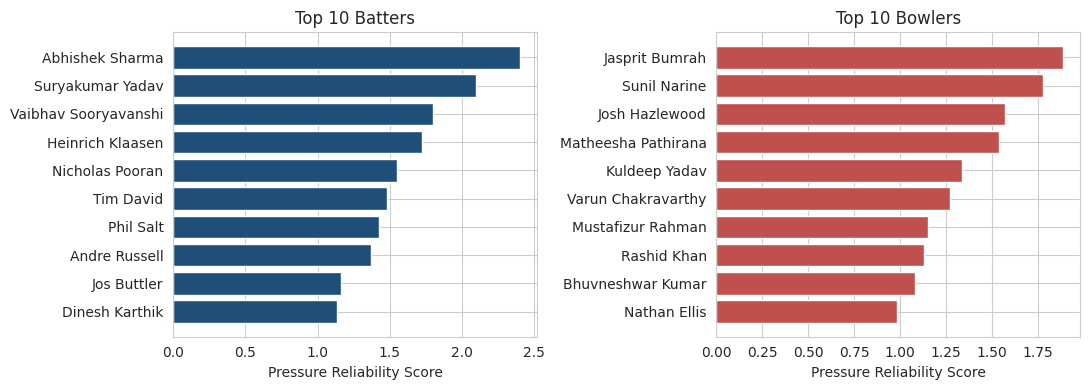

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, role, title, col in zip(ax, ("bat", "bowl"), ("Top 10 Batters", "Top 10 Bowlers"), ("#1F4E79", "#C0504D")):
    t = RESULT[role].head(10).iloc[::-1]
    a.barh(t.player, t.score, color=col);  a.set_title(title);  a.set_xlabel("Pressure Reliability Score")
plt.tight_layout();  plt.show()

## Bonus 2: How stable is the ranking? (Bootstrap)

**The idea:** randomly sample matches many times and calculate the rankings again. A player who appears in the Top 10 in most runs has a more stable position. A player who moves in and out of the Top 10 is a closer call.

Increasing `N_BOOT` gives a more detailed picture, but also takes longer. The notebook uses 50 runs by default. The report used 250 runs.

In [14]:
N_BOOT = 50
match_ids = np.sort(balls.match_id.unique());  rng = np.random.default_rng(11)
for role in ("bat", "bowl"):
    top = RESULT[role].index[:10];  elig_ids = RESULT[role].index
    hits = pd.Series(0.0, index=elig_ids)
    for k in range(N_BOOT):
        w = pd.Series(np.bincount(rng.integers(0, len(match_ids), len(match_ids)), minlength=len(match_ids)), index=match_ids)
        r = final_scores(TABLES[role], w=w, H=HYPER[role]);  r = r[r.eligible].sort_values("score", ascending=False)
        hits[[i for i in r.index[:10] if i in hits.index]] += 1
    RESULT[role]["chance_in_top10"] = (hits / N_BOOT).values
    print(f"\n{role.upper()} - top 10 me aane ka chance (%)")
    display((RESULT[role][["rank", "player", "chance_in_top10"]].head(10).assign(
        chance_in_top10=lambda d: (d.chance_in_top10 * 100).round(0))).reset_index(drop=True))


BAT - top 10 me aane ka chance (%)


,rank,player,chance_in_top10
0,1,Abhishek Sharma,96.0
1,2,Suryakumar Yadav,92.0
2,3,Vaibhav Sooryavanshi,80.0
3,4,Heinrich Klaasen,82.0
4,5,Nicholas Pooran,82.0
5,6,Tim David,66.0
6,7,Phil Salt,66.0
7,8,Andre Russell,42.0
8,9,Jos Buttler,52.0
9,10,Dinesh Karthik,30.0



BOWL - top 10 me aane ka chance (%)


,rank,player,chance_in_top10
0,1,Jasprit Bumrah,80.0
1,2,Sunil Narine,80.0
2,3,Josh Hazlewood,58.0
3,4,Matheesha Pathirana,76.0
4,5,Kuldeep Yadav,46.0
5,6,Varun Chakravarthy,64.0
6,7,Mustafizur Rahman,52.0
7,8,Rashid Khan,38.0
8,9,Bhuvneshwar Kumar,44.0
9,10,Nathan Ellis,32.0


## Bonus 3: Download the results

The full rankings for all eligible players are saved as CSV files.

In [15]:
RESULT["bat"].round(3).to_csv("full_ranking_batters.csv")
RESULT["bowl"].round(3).to_csv("full_ranking_bowlers.csv")
try:
    from google.colab import files
    files.download("full_ranking_batters.csv");  files.download("full_ranking_bowlers.csv")
except ImportError:
    print("The CSV files have been saved in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

### Quick recap

1. **Pressure** — how much the next delivery could change the team's win probability (Leverage Index).
2. **Performance** — how much better or worse the player performs than expected in that situation.
3. **Rating** — usual skill, change under pressure and consistency, adjusted to account for limited data.
4. **Final ranking** — the average score across four pressure definitions.

**Keep in mind:** the batter results show a more reliable signal than the bowler results. The bowler rankings are less certain because pressure-specific bowling data is limited and more variable. The Top 10 group is more meaningful than treating every exact position as certain.